# 3. Processing in chunks

In notebook 2, every step worked on one minute of data loaded in memory. A real-time system
cannot do that: data arrive in small packets, a fraction of a second each, and each packet
must be processed as soon as it arrives. Archives that do not fit in memory raise the same
problem.

In this notebook you will:
1. see why processing chunk by chunk breaks naive code,
2. turn the preprocessing into a pipeline of **atoms**, which carry their memory from one
   chunk to the next,
3. write your own atom: a continuous STA/LTA,
4. pick both cables over their whole record, chunk by chunk,
5. locate the earthquake from the stream of picks.

Notebook 4 plugs the same pipeline into a live stream.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/home/trabatto/projects/indonesia/lmi-sir


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sp
import xdas as xd
from xdas.atoms import Atom, State

from tools import Locator

The functions written in notebook 2, and the minute of the north cable around the
earthquake. The gain is left out: the STA/LTA ratio does not depend on the units.

In [3]:
def preprocess(da):
    da = xd.filter(da, (2.0, 15.0), dim="time")
    da = xd.filter(da, (None, 0.01), dim="distance")
    da = xd.resample(da, 50.0, dim="time")
    da = xd.resample(da, interval=45.0, snap=True, dim="distance")
    return da


def stalta(da, sta, lta):
    dt = da["time"].get_sampling_interval()
    csta, clta = dt / sta, dt / lta
    power = da.values ** 2
    short = sp.lfilter([csta], [1, csta - 1], power, axis=0)
    long = sp.lfilter([clta], [1, clta - 1], power, axis=0)
    ratio = short / long
    ratio[: round(lta / dt)] = 0  # the long average is not settled yet
    return da.copy(data=ratio)


abyss = xd.open("abyss.nc")
event = abyss["N"].sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=slice(5000, 97000)).load()
processed = preprocess(event)
ratio = stalta(processed, sta=0.2, lta=5.0)

## The problem

Pretend the minute arrives in pieces of 10 s, one per file.

**Task:** split `processed` into 6 chunks along time, apply `stalta` to each chunk, then put
the results back together. Plot it next to `ratio` (computed on the whole minute). What goes
wrong, and why?

> **Reminder:**
> ```python
> chunks = xd.split(da, 10, dim="x")     # a list of 10 arrays of (almost) equal size along "x"
> xd.concatenate(chunks, dim="x")        # back to one array
> [f(chunk) for chunk in chunks]         # apply f to each element of a list
> ```

📖 [`xdas.split`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.split.html) ·
[`xdas.concatenate`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.concatenate.html)

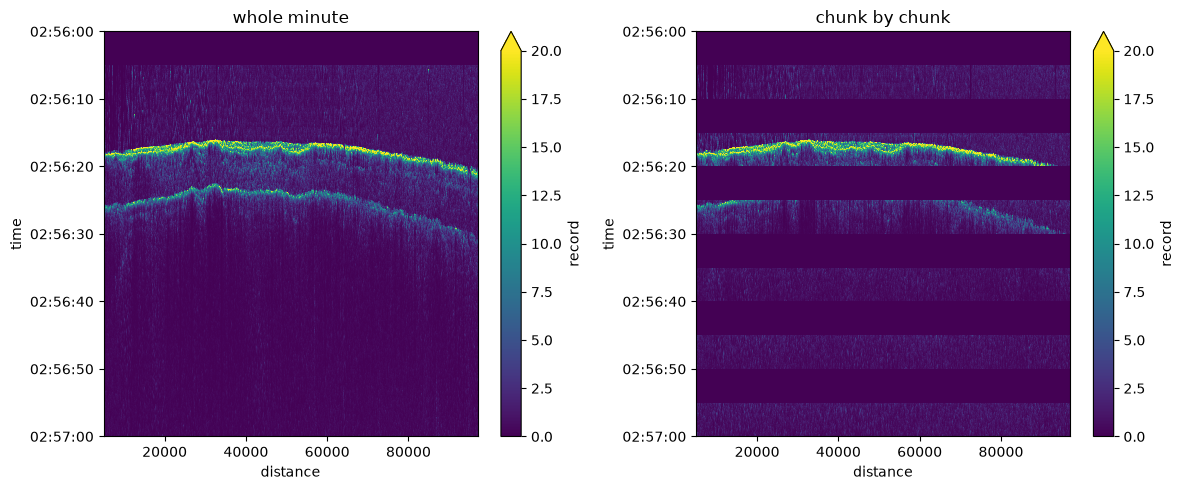

In [4]:
chunks = xd.split(processed, 6, dim="time")
naive = xd.concatenate([stalta(chunk, sta=0.2, lta=5.0) for chunk in chunks], dim="time")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ratio.plot(ax=axes[0], vmin=0, vmax=20, yincrease=False)
naive.plot(ax=axes[1], vmin=0, vmax=20, yincrease=False)
axes[0].set_title("whole minute")
axes[1].set_title("chunk by chunk")
fig.tight_layout()

## Atoms

Each chunk starts from scratch: the averages restart from zero and the first 5 s of each
chunk are blanked. The filters of `preprocess` have the same problem, only less visible. The
fix is to keep a **state**: what each step must remember from the previous chunk (the last
values of the averages, of the filters, ...).

Xdas does this with **atoms**. Every processing function also exists as an atom: call it with
`...` in place of the data, and it returns the step itself instead of a result. Atoms chain
with `>>` into a pipeline, which is called like a function. Called on chunks with
`chunk_dim="time"`, a pipeline keeps its state between calls.

**Task:** rewrite `preprocess` as a pipeline of atoms.

> **Reminder:**
> ```python
> xd.filter(da, (1.0, 5.0), dim="x")         # a function: filters da now
> xd.filter(..., (1.0, 5.0), dim="x")        # an atom: will filter what it is given later
> pipeline = atom1 >> atom2 >> atom3         # chain atoms (wrap long chains in parentheses)
> pipeline(da)                               # run it on a whole array
> pipeline(chunk, chunk_dim="x")             # run it on the next chunk along "x"
> ```

📖 [Composing a processing sequence](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/atoms.html)

In [5]:
pipeline = (
    xd.filter(..., (2.0, 15.0), dim="time")
    >> xd.filter(..., (None, 0.01), dim="distance")
    >> xd.resample(..., 50.0, dim="time")
    >> xd.resample(..., interval=45.0, snap=True, dim="distance")
)
pipeline

Sequential:
  0: Filter(freq=(2.0, 15.0))
  1: Filter(freq=(None, 0.01), dim='distance')
  2: Resample(rate=50.0)
  3: Resample(interval=45.0, snap=True, dim='distance')

Instead of writing the loop over chunks, `.process` does it for you: it cuts the input into
chunks, feeds them to the pipeline in order and joins the results.

**Task:** run `pipeline` on `event` by chunks of 100 samples, and check that the result is the
same as `processed`.

> **Reminder:**
> ```python
> result = pipeline.process(da, chunks={"x": 100})   # chunks of 100 samples along "x"
> np.abs(a.values - b.values).max()                  # largest difference between two arrays
> ```

📖 [Processing larger-than-memory data](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/processing.html)

In [6]:
chunked = pipeline.process(event, chunks={"time": 100})
np.abs(chunked.values - processed.values).max()

np.float64(0.0)

## A continuous STA/LTA

Our `stalta` has no atom yet: let us write it. An atom is a class with three methods:
- `__init__` stores the parameters, and declares each state as `State(...)` (not known yet);
- `initialize` is called on the first chunk: it sets the initial states;
- `call` processes one chunk, using the states and updating them.

The recursion of notebook 2 only needs the last value of each average, which `sp.lfilter` can
take as an input (`zi`) and give back as an output (`zf`). The number of samples already seen
tells which samples still lie in the first `lta` seconds, where the ratio is blanked.

**Task:** complete `call`: run the two recursions starting from the stored states, then store
the new states.

> **Reminder:**
> ```python
> y, zf = sp.lfilter(b, a, x, axis=0, zi=zi)  # zi: state before x, zf: state after x
>                                              # (zi of shape (1, n channels) for our filters)
> self.thing = State(new_value)                # update a state (always with State)
> self.thing                                   # read a state
> ```

📖 [Defining custom atoms](https://xdas.readthedocs.io/en/stable/user-guide/pipeline/atoms.html#defining-custom-atoms)

In [7]:
class STALTA(Atom):
    def __init__(self, sta, lta):
        super().__init__()
        self.sta = sta
        self.lta = lta
        self.short = State(...)
        self.long = State(...)
        self.count = State(...)

    def initialize(self, da, **flags):
        self.short = State(np.zeros((1, da.sizes["distance"])))
        self.long = State(np.zeros((1, da.sizes["distance"])))
        self.count = State(0)

    def call(self, da, **flags):
        dt = da["time"].get_sampling_interval()
        csta, clta = dt / self.sta, dt / self.lta
        power = da.values ** 2
        short, zshort = sp.lfilter([csta], [1, csta - 1], power, axis=0, zi=self.short)
        long, zlong = sp.lfilter([clta], [1, clta - 1], power, axis=0, zi=self.long)
        self.short = State(zshort)
        self.long = State(zlong)
        ratio = short / long
        ratio[: max(round(self.lta / dt) - self.count, 0)] = 0  # the long average is not settled yet
        self.count = State(self.count + len(ratio))
        return da.copy(data=ratio)

**Task:** run your atom on the 6 chunks of `processed`, one call per chunk (it has to keep
its state: pass `chunk_dim`), put the results together and compare with `ratio`.

In [8]:
atom = STALTA(sta=0.2, lta=5.0)
continuous = xd.concatenate([atom(chunk, chunk_dim="time") for chunk in chunks], dim="time")
np.abs(continuous.values - ratio.values).max()

np.float64(0.0)

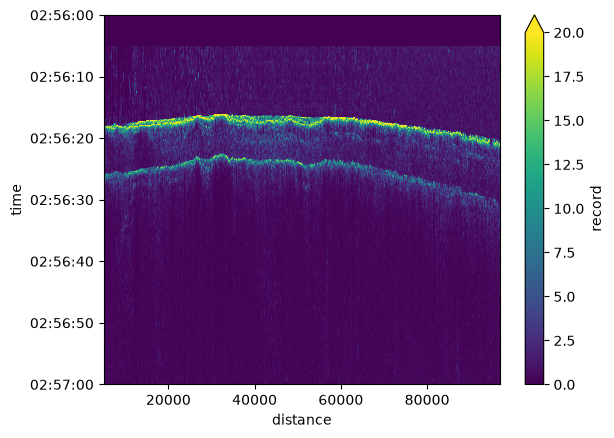

In [9]:
continuous.plot(vmin=0, vmax=20, yincrease=False)

## The whole record

Your atom now fits in the pipeline, followed by the trigger: `xd.trigger` also exists as an
atom, which outputs tables of picks.

**Task:** build the full pipeline (preprocessing, STA/LTA, trigger) and run it on both cables,
over their whole 4 min record. As in notebook 2, keep only the channels in the sea.

> **Reminder:**
> - a `DataCollection` can be built from a dict: `xd.DataCollection({"a": da1, "b": da2}, "name")`;
>   `"name"` names the level (here: the cable);
> - `.process` on a collection runs each array in turn (each with a fresh state), and returns one
>   table for all, with one column per level of the collection;
> - without `chunks`, `.process` follows the files on disk: one chunk per file (10 s).

📖 [`xdas.trigger`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.trigger.html)

In [10]:
keep = {"N": slice(5000, 97000), "S": slice(5000, 130000)}
sea = xd.DataCollection({cable: abyss[cable].sel(distance=keep[cable]) for cable in abyss}, "cable")

picker = (
    pipeline
    >> STALTA(sta=0.2, lta=5.0)
    >> xd.trigger(..., thresh=8.0, coords=["distance", "longitude", "latitude", "depth", "time"])
)
picks = picker.process(sea)
picks

,cable,distance,longitude,latitude,depth,time,value
0,N,5101.394453,-71.279206,-29.887853,6.6,2024-09-02 02:56:25.860,14.089248
1,N,5147.352962,-71.279661,-29.887748,7.1,2024-09-02 02:56:25.960,14.304450
2,N,5193.311470,-71.280116,-29.887643,7.5,2024-09-02 02:56:18.160,8.192045
3,N,5193.311470,-71.280116,-29.887643,7.5,2024-09-02 02:56:25.920,15.477774
4,N,5239.269979,-71.280570,-29.887539,8.0,2024-09-02 02:56:18.280,13.415019
...,...,...,...,...,...,...,...
10280,S,128454.031495,-71.841324,-30.706284,1908.2,2024-09-02 02:58:41.300,20.058761
10281,S,128499.990003,-71.841366,-30.706697,1898.6,2024-09-02 02:58:41.380,19.809917
10282,S,128545.948512,-71.841407,-30.707101,1889.1,2024-09-02 02:58:41.380,16.660817
10283,S,128591.907020,-71.841448,-30.707505,1879.7,2024-09-02 02:58:41.460,10.117862


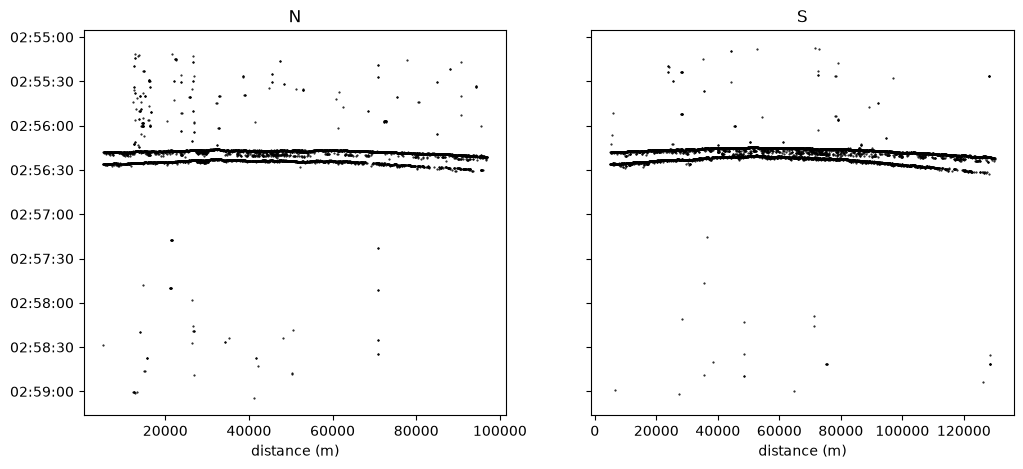

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (cable, table) in zip(axes, picks.groupby("cable")):
    ax.plot(table["distance"], table["time"], "k.", markersize=1)
    ax.set_title(cable)
    ax.set_xlabel("distance (m)")
axes[0].invert_yaxis()

## Locating from a stream of picks

In a stream, picks come a few at a time, and nobody tells us when an earthquake is over.
`Locator` (in `tools.py`) works like an atom: it keeps the picks it has not used yet, and is
called with the new picks and the current time. It waits for a burst of picks (many channels
within 2 s), then 20 s more for the waves to cross the cables, and then locates with the first
pick of each channel. Isolated picks are dropped as noise.

**Task:** replay the picks second by second: at each step, give the locator the picks of the
last second. Print the locations it returns. When does it answer, compared with the origin
time? Compare with notebook 2 and with EMSC (71.800°W, 29.954°S, 50 km, 02:56:07.37).

> **Reminder:**
> ```python
> pd.date_range("2024-01-01T00:00:00", "2024-01-01T00:01:00", freq="1s")  # times every second
> pd.Timedelta(seconds=1)                       # a duration
> table[(table["time"] >= a) & (table["time"] < b)]  # the rows between two times
> ```

In [12]:
locator = Locator()
for now in pd.date_range("2024-09-02T02:55:00", "2024-09-02T02:59:10", freq="1s"):
    new = picks[(picks["time"] >= now - pd.Timedelta(seconds=1)) & (picks["time"] < now)]
    location = locator(new, now)
    if location is not None:
        print(now)
        print(location)

2024-09-02 02:56:33
longitude                        -71.84
latitude                         -29.96
depth                           50000.0
time         2024-09-02 02:56:07.600000
picks                              4706
dtype: object
